# Годовой проект
## Чекпоинт 2. EDA
##### Исполнитель работы: Куренков Иван Андреевич
---
### 1. Цель исследования и описание данных
Цель исследования - изучить качество и структуру данных Telco Customer Churn и выявить признаки, связанные с оттоком клиентов.

В выбранном датасете каждая строка представляет собой клиента, а каждый столбец содержит атрибуты. Целевой переменной является атрибут Churn, который принимает два значения - ушёл клиент (Yes) или нет (No). Таким образом мы рассматриваем задачу классификации с двумя классами.

---

### 2. Загрузка данных и первичный обзор

Для начала загрузим данные из файла и посмотрим на их размер:

In [1]:
import pandas as pd

data = pd.read_csv('../data/raw/Telco-Customer-Churn.csv')
data.shape

(7043, 21)

Видим, что датасет содержит 7043 записи и 19 признаков, идентификатор и целевая переменная.

Изучим, какие типы данных хранятся в столбцах:

In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Видим 18 строковых столбцов, 2 типа int64 и 1 float64.

Имеющиеся столбцы:

0) Уникальный ID
1) Пол абонента
2) Является ли абонент пожилым человеком
3) Имеется ли у абонента партнёр/супруг(а)
4) Имеется ли у абонента иждивенец
5) Число месяцев, на протяжении которых абонент пользовался услугами
6) Подключена ли у абонента телефонная связь
7) Поключены ли у абонента несколько телефонных линий
8) Тип интернет-подключения абонента
9) Подключена ли у абонента услуга онлайн-безопасности
10) Подключена ли у абонента услуга онлайн-резервного копирования
11) Подключена ли у абонента услуга защиты устройства
12) Подключена ли у абонента услуга технической поддержки
13) Подключена ли у абонента услуга стримингового ТВ
14) Подключена ли у абонента услуга стриминга кинофильмов
15) По какому договору обслуживается абонент
16) Использование абонентом цифрого счёта вместо бумажного
17) Каким способом оплаты пользуется абонент
18) Величина месячного платежа
19) Сумма общих платежей
20) Ушёл ли абонент (target)

---

### 3. Проверка качества данных

data.info() не выявил явных пропусков. При последующей проверке обнаружены 11 пустых строк в TotalCharges.

Ниже изучим подробное описание всех столбцов:

In [3]:
data.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


В имеющихся данных подавляющее число столбцов имеет строковый тип. Поэтому о наличии аномалий в их данных можно судить только по количеству уникальных значений в каждом признакеи по самим значениям. В нашем случае уникальные значения и их количество не вызывают подозрений. В статистических данных числовых столбцов аномалий также не обнаружено.

Посмотрим уникальные значения для каждого строкового признака:

In [4]:
for column in data.select_dtypes(include=('object', 'string')).columns:
    print(f'\nСтолбец: {column}')
    print(f'Значениея: {data[column].unique()}')


Столбец: customerID
Значениея: <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

Столбец: gender
Значениея: <StringArray>
['Female', 'Male']
Length: 2, dtype: str

Столбец: Partner
Значениея: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Столбец: Dependents
Значениея: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Столбец: PhoneService
Значениея: <StringArray>
['No', 'Yes']
Length: 2, dtype: str

Столбец: MultipleLines
Значениея: <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

Столбец: InternetService
Значениея: <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Столбец: OnlineSecurity
Значениея: <StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: 

Никаких аномальных значений у строковых фичей не выявлено.

Проверим данные на наличие дубликатов:

In [5]:
data.duplicated().sum()

np.int64(0)

Полных дубликатов не обнаружено.

Так как столбец TotalCharges имеет строковый вид, попробуем привести его к числовому и посмотреть на его статистику:

In [6]:
total_charges_numeric = pd.to_numeric(
    data['TotalCharges'],
    errors='coerce'
)

total_charges_numeric.describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

In [7]:
invalid_total_charges = total_charges_numeric.isna()

print('Количество отсутствующих или нечисловых значений:', invalid_total_charges.sum())

data.loc[invalid_total_charges, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']]

Количество отсутствующих или нечисловых значений: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


Обнаружено 11 строк с пустым значением TotalCharges. Во всех этих строках tenure = 0, а Churn = 'No'. Предположительно, это недавно подключённые клиенты, для которых ещё не сформировалась сумма накопленных начислений. Таким образом, пропуски могут быть связаны с начальным этапом обслуживания, а не со случайной потерей данных.

Преобразуем столбец TotalCharges нашего датафрейма в чиловой, а пропущенные значения заполним нулями:

In [8]:
data['TotalCharges'] = pd.to_numeric(
    data['TotalCharges'],
    errors='coerce'
)

missing_mask = data['TotalCharges'].isna()

data.loc[missing_mask, 'TotalCharges'] = 0

---

### 4. Анализ целевой переменной
Посмотрим, как распределены значения target:

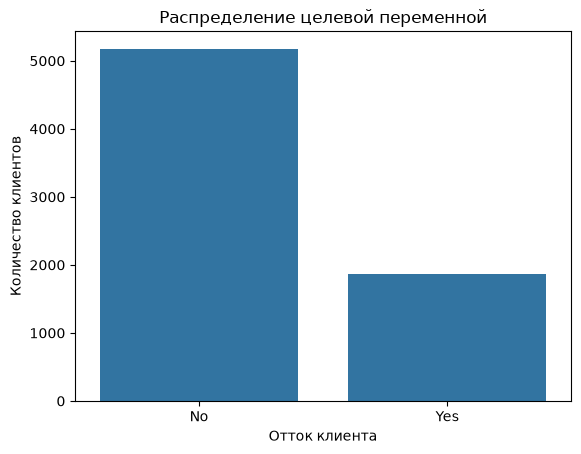

Churn
No     5174
Yes    1869
Name: count, dtype: int64 
 Churn
No     73.463
Yes    26.537
Name: proportion, dtype: float64


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=data, x='Churn', order=['No', 'Yes'])

plt.title('Распределение целевой переменной')
plt.xlabel('Отток клиента')
plt.ylabel('Количество клиентов')
plt.show()

print(data['Churn'].value_counts(), '\n', data['Churn'].value_counts(normalize=True).mul(100).round(3))

Соотношение размеров классов имеет величину 3 : 1, остались ~73.5% клиентов в количестве 5174 человек, а ушли ~26.5% клиентов в количестве 1869 человек.

---

### 5. Анализ отдельных признаков

Для начала рассмотрим числовые признаки и построим для каждого гистограмму и boxplot:

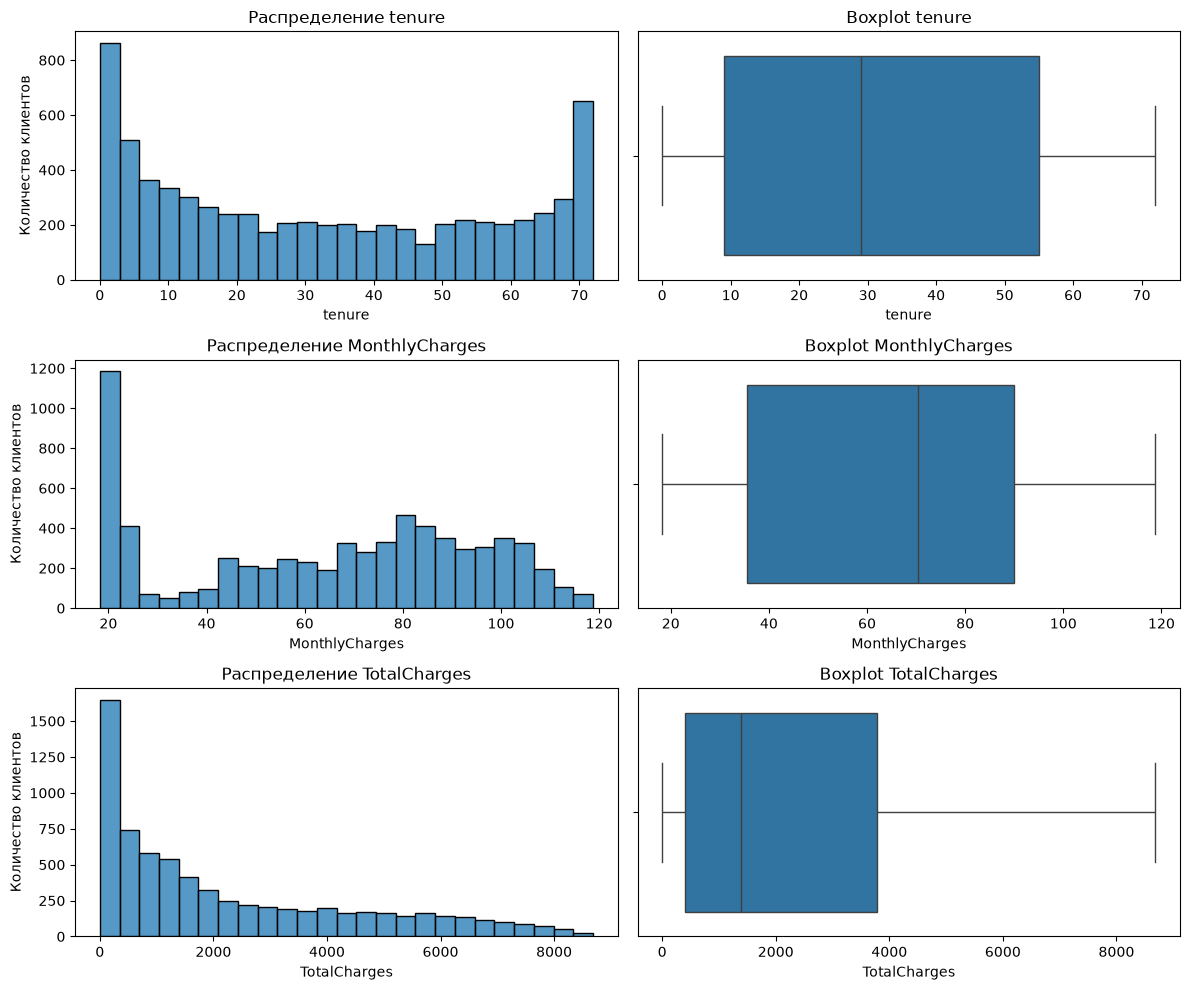

In [10]:
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for row, column in enumerate(numeric_columns):
    sns.histplot(
        data=data,
        x=column,
        bins=25,
        ax=axes[row, 0]
    )
    axes[row, 0].set_title(f'Распределение {column}')
    axes[row, 0].set_ylabel('Количество клиентов')

    sns.boxplot(
        data=data,
        x=column,
        ax=axes[row, 1]
    )
    axes[row, 1].set_title(f'Boxplot {column}')

plt.tight_layout()
plt.show()

tenure:
- Значения находятся примерно в диапазоне от 0 до 72 месяцев, медиана - около 29 месяцев.

- Распределение имеет выраженные пики у начала и конца диапазона: в выборке много как недавно подключённых клиентов, так и клиентов с длительным сроком обслуживания.

MonthlyCharges:
- Значения находятся примерно в диапазоне от 18 до 119, медиана - около 70.

- Есть выраженный пик в районе 20 и несколько менее выраженных пиков среди более высоких платежей.

TotalCharges:
- Распределение правосторонне-асимметричное: большинство значений сосредоточено в нижней части диапазона, а вправо тянется длинный хвост.

- Медиана составляет примерно 1400; встречаются значения выше 8000.

Теперь посмотрим на распределение значений категориальных столбцов:

        Количество   Доля, %
gender                      
Male          3555  50.47565
Female        3488  49.52435 

               Количество    Доля, %
SeniorCitizen                       
0                    5901  83.785319
1                    1142  16.214681 

         Количество   Доля, %
Partner                      
No             3641  51.69672
Yes            3402  48.30328 

            Количество    Доля, %
Dependents                       
No                4933  70.041176
Yes               2110  29.958824 

              Количество    Доля, %
PhoneService                       
Yes                 6361  90.316626
No                   682   9.683374 

                  Количество    Доля, %
MultipleLines                          
No                      3390  48.132898
Yes                     2971  42.183729
No phone service         682   9.683374 

                 Количество    Доля, %
InternetService                       
Fiber optic            3096  43.958540
DSL    

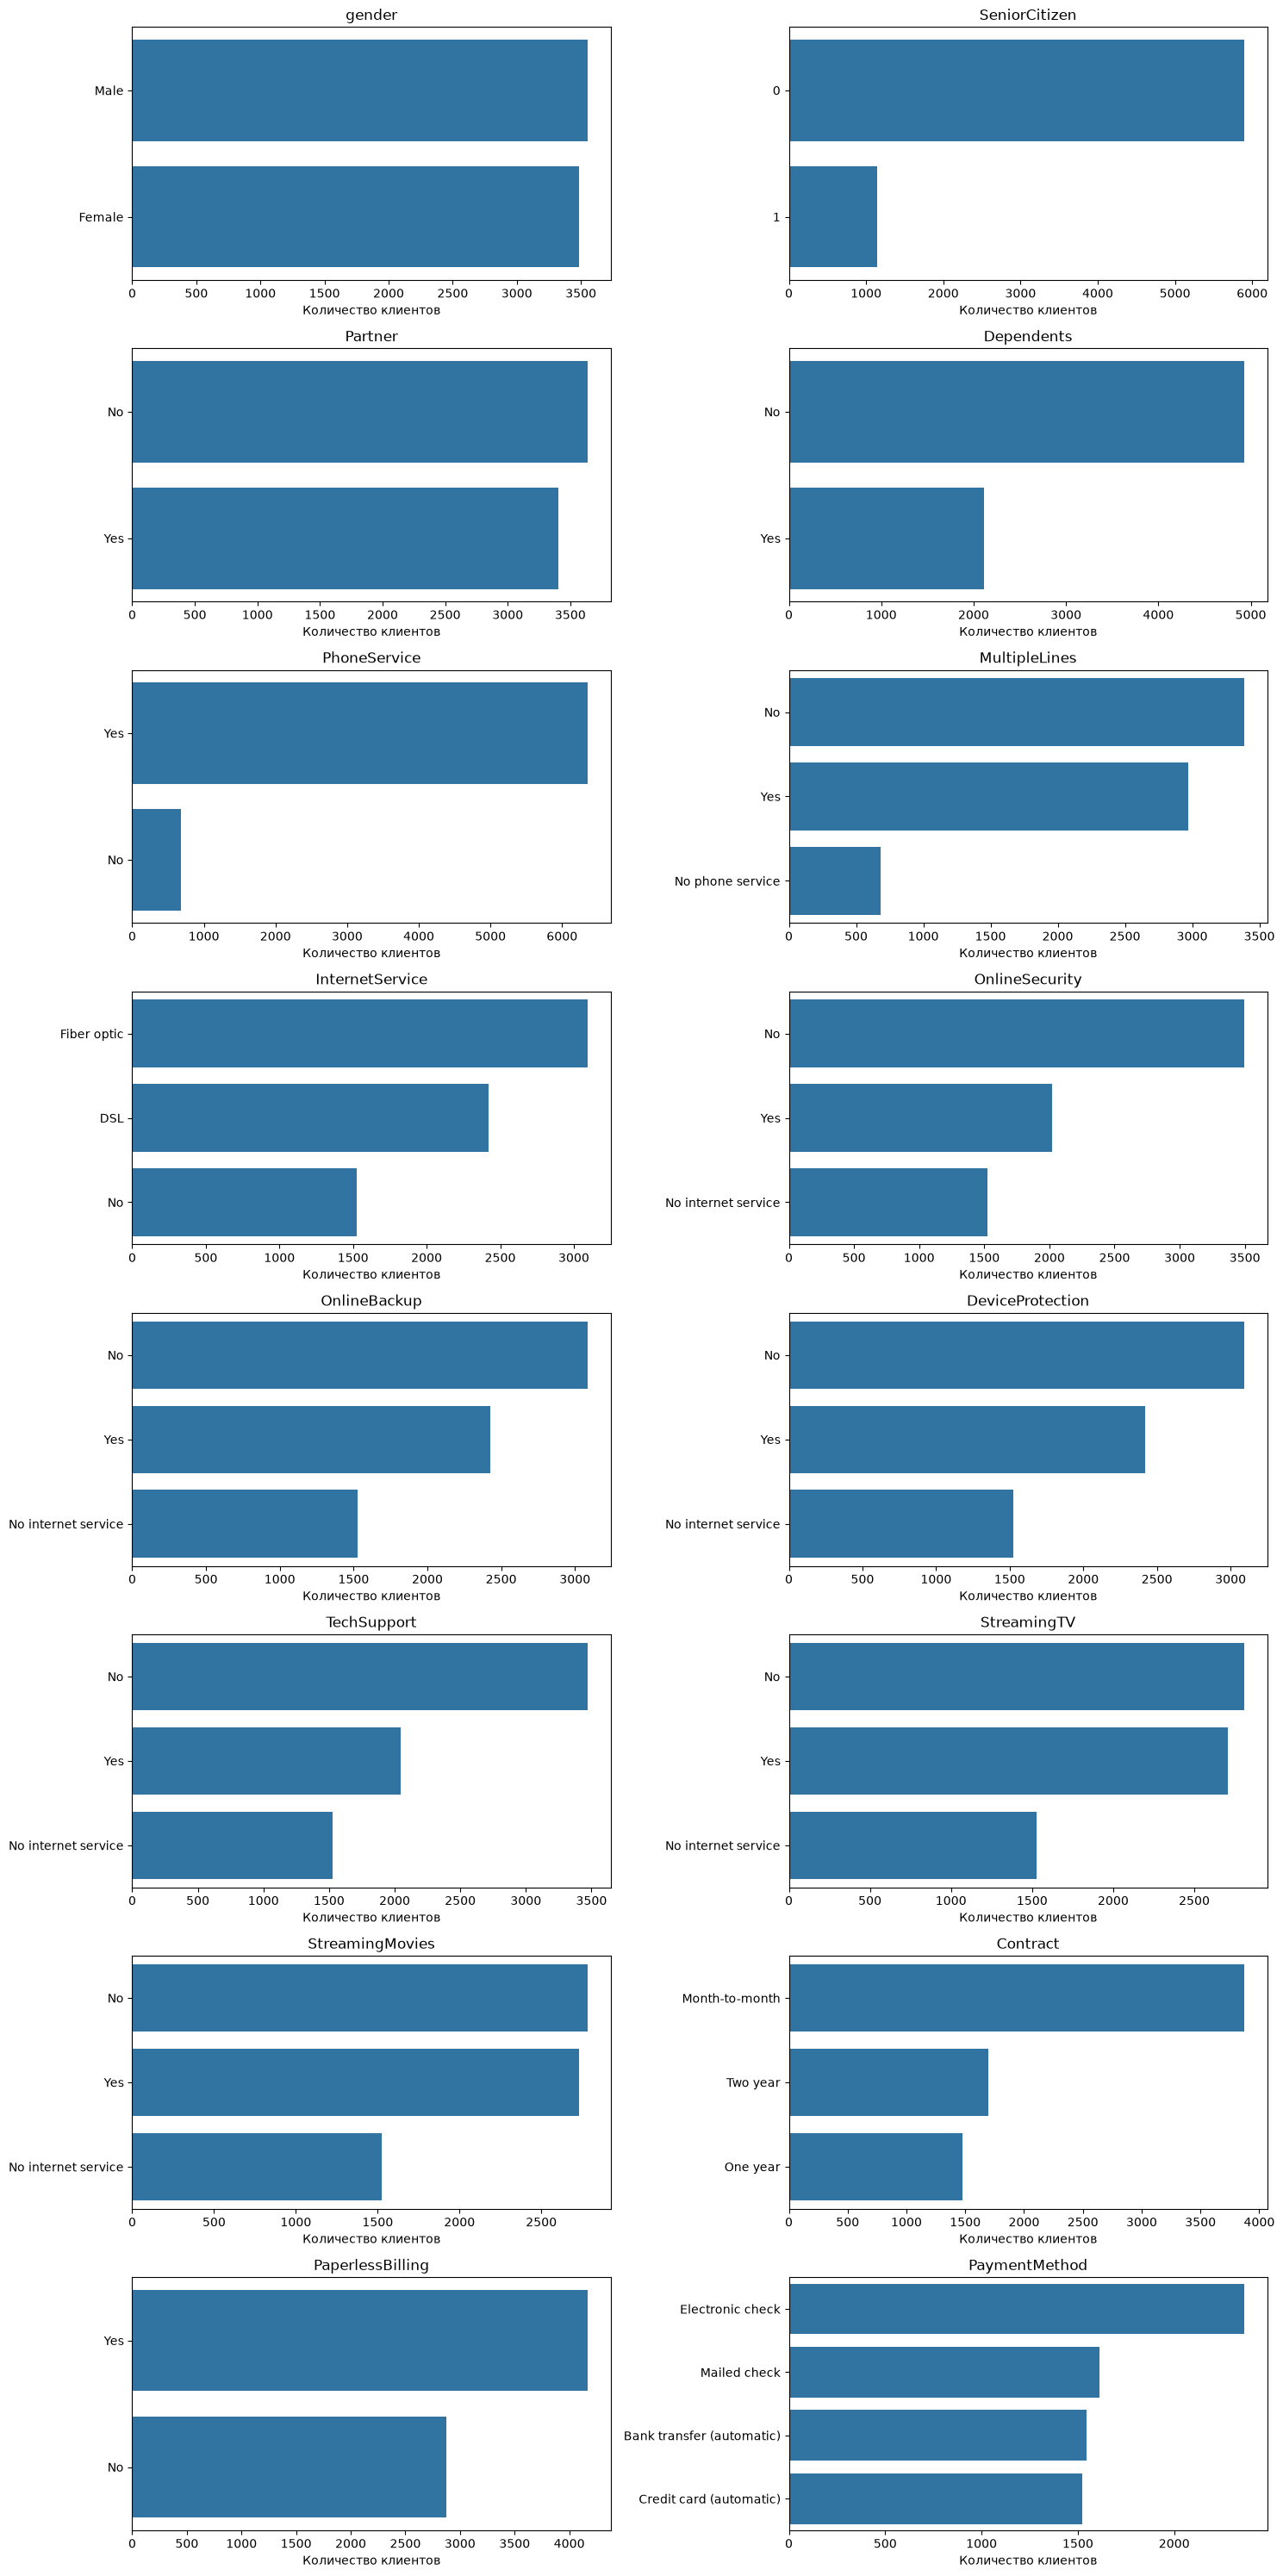

In [11]:
categorical_columns = [
    column for column in data.columns
    if column not in numeric_columns + ['customerID', 'Churn']
]

fig, axes = plt.subplots(8, 2, figsize=(15, 30))
axes = axes.flatten()

for ax, column in zip(axes, categorical_columns):
    order = data[column].value_counts().index

    sns.countplot(
        data=data,
        y=column,
        order=order,
        ax=ax
    )

    ax.set_title(column)
    ax.set_xlabel('Количество клиентов')
    ax.set_ylabel('')


for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

for column in categorical_columns:
        print(pd.DataFrame({
        'Количество': data[column].value_counts(),
        'Доля, %': data[column].value_counts(normalize=True).mul(100),
    }), '\n')

plt.tight_layout()
plt.show()

Характеристики клиентов
- Мужчины и женщины представлены практически поровну: 50,5% и 49,5%.

- Пожилые клиенты составляют 16,2% выборки.

- Наличие партнёра распределено почти равномерно: у 48,3% он есть, у 51,7% - нет.

- У большинства клиентов нет иждивенцев - 70,0%.

Подключённые услуги
- Телефонная связь подключена у 90,3% клиентов. Несколько телефонных линий используют 42,2% от всей выборки.

- Оптоволоконный интернет используют 44,0%, DSL - 34,4%. У 21,7% клиентов интернет не подключён.

- Дополнительные интернет-услуги подключены у 28,7–38,8% всех клиентов. Среди них реже всего - встречается онлайн-безопасность, чаще всего - стриминг фильмов.

- Для каждой дополнительной интернет-услуги категория No internet service содержит одинаковое число клиентов - 1526. Аналогично, число клиентов без телефонной связи совпадает с численностью категории No phone service в MultipleLines - 682.

Договоры и оплата
- Более половины клиентов имеют помесячный договор - 55,0%. Договоры на один и два года встречаются реже: 20,9% и 24,1%.

- Электронные счета используют 59,2% клиентов.

- Самый распространённый способ оплаты - Electronic check (33,6%). Остальные способы представлены примерно равными долями - от 21,6% до 22,9%.

Общий итог:

Во всех рассмотренных категориях есть сотни или тысячи клиентов; единичных категорий не обнаружено. При этом некоторые группы заметно меньше других - например, клиенты без телефонной связи и пожилые клиенты.

---

### 6. Взаимосвязь признаков с целевой переменной
Сначала посмотрим на числовые признаки:

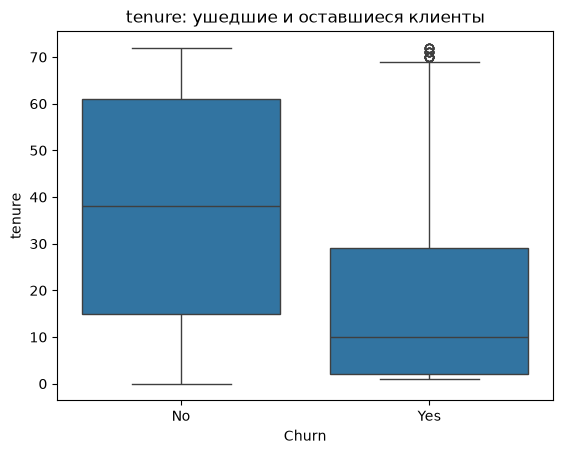

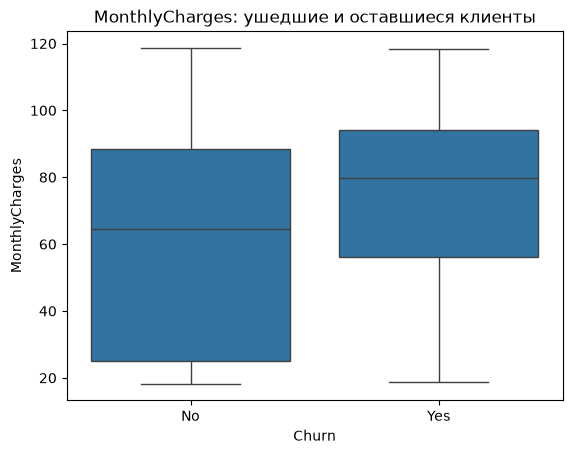

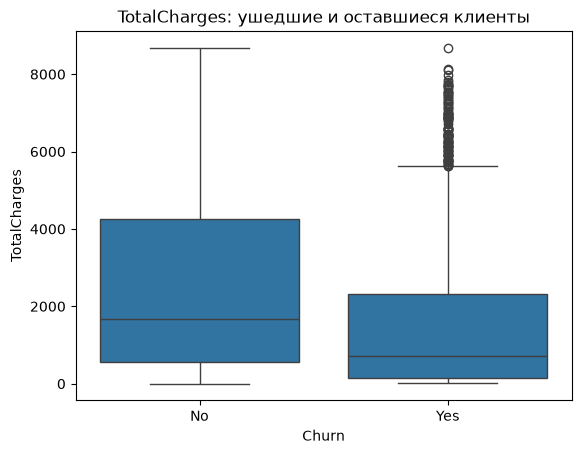

In [12]:
numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

for column in numeric_columns:
    sns.boxplot(data=data, x='Churn', y=column)

    plt.title(f'{column}: ушедшие и оставшиеся клиенты')
    plt.show()

Из полученных диаграмм можно заметить, что среди ушедших клиентов длительность обслуживания обычно меньше, а тарифы - дороже. На построенных boxplot потенциальные выбросы за пределами усов не выделены. Крайние значения длительности обслуживания и начислений не выглядят очевидно ошибочными. На данном этапе наблюдения не удаляем.

Теперь рассмотрим категориальные признаки:


Признак: gender


Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


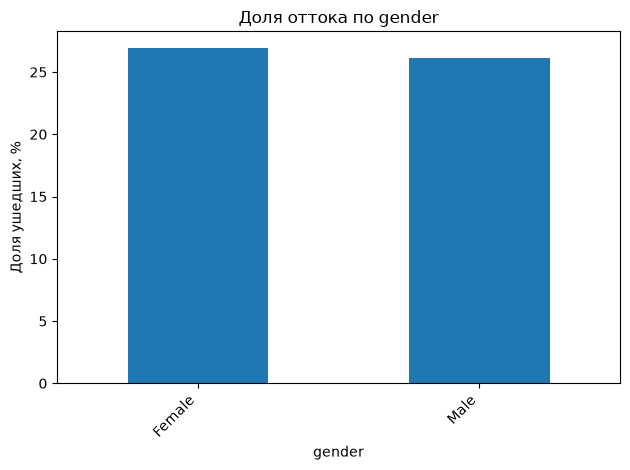


Признак: SeniorCitizen


Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


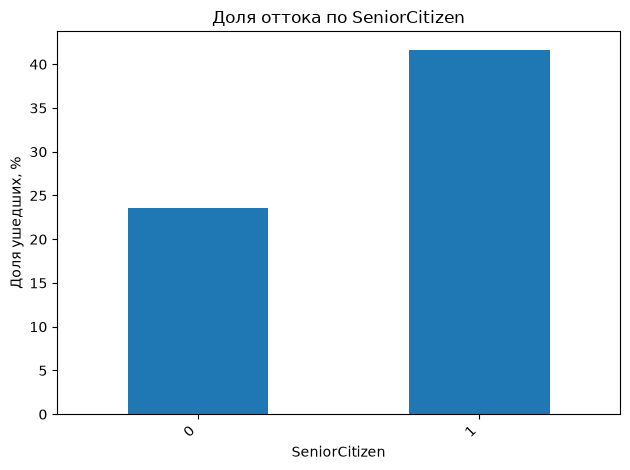


Признак: Partner


Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


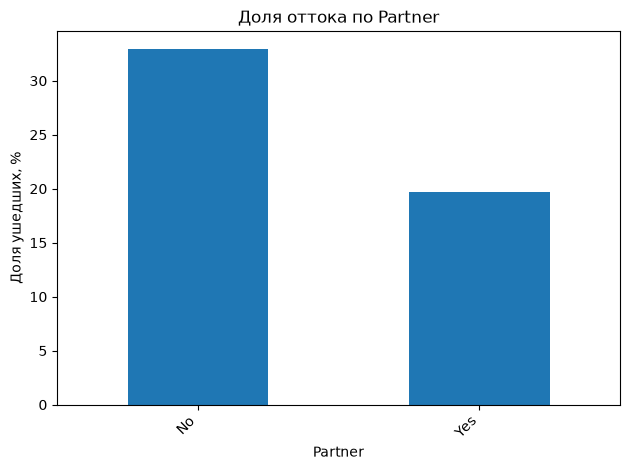


Признак: Dependents


Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


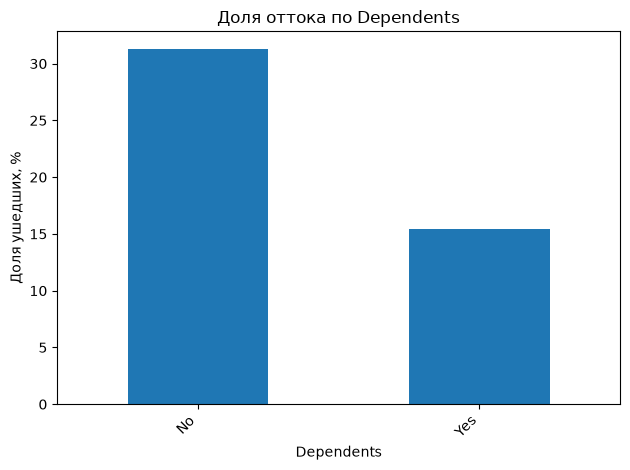


Признак: PhoneService


Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699


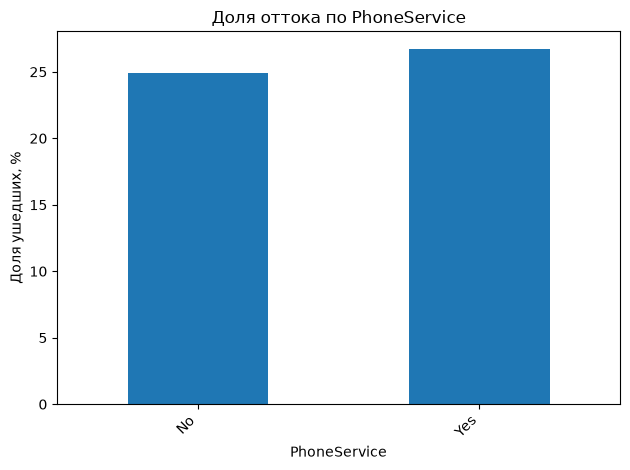


Признак: MultipleLines


Churn,No,Yes
MultipleLines,,
No,2541,849
No phone service,512,170
Yes,2121,850


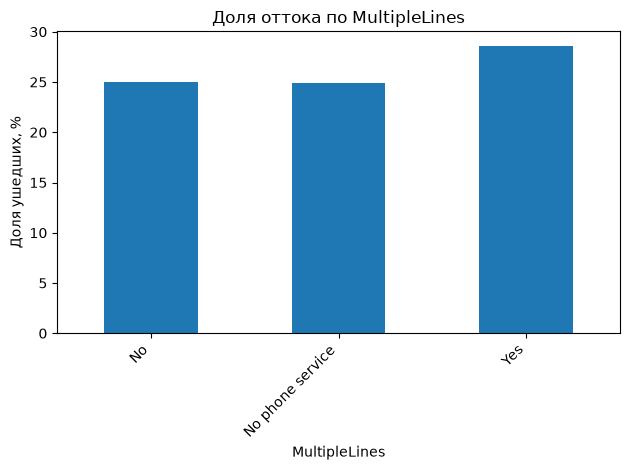


Признак: InternetService


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


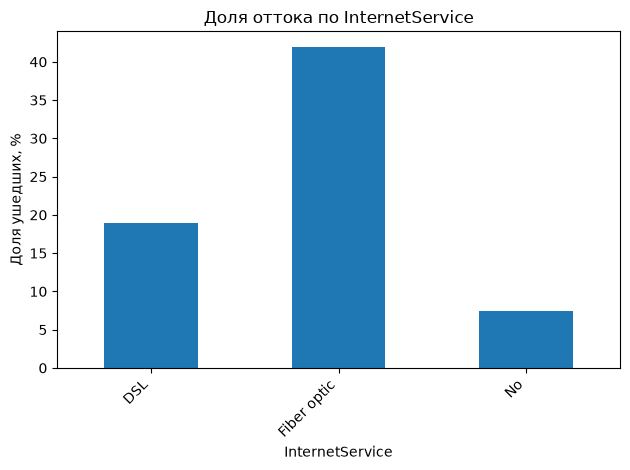


Признак: OnlineSecurity


Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


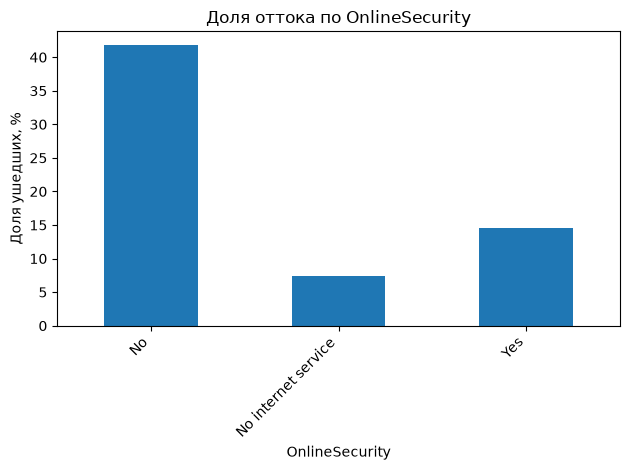


Признак: OnlineBackup


Churn,No,Yes
OnlineBackup,,
No,1855,1233
No internet service,1413,113
Yes,1906,523


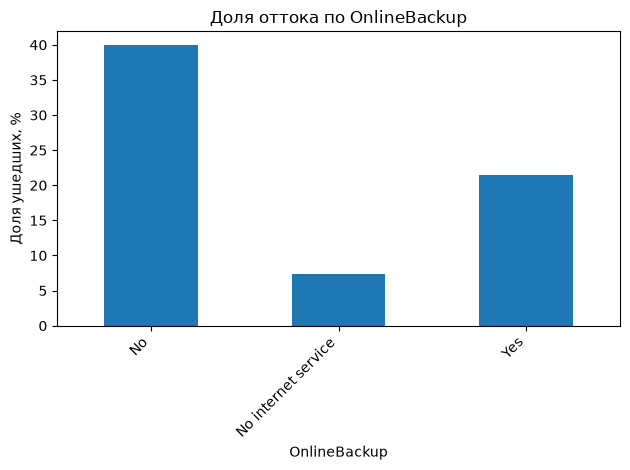


Признак: DeviceProtection


Churn,No,Yes
DeviceProtection,,
No,1884,1211
No internet service,1413,113
Yes,1877,545


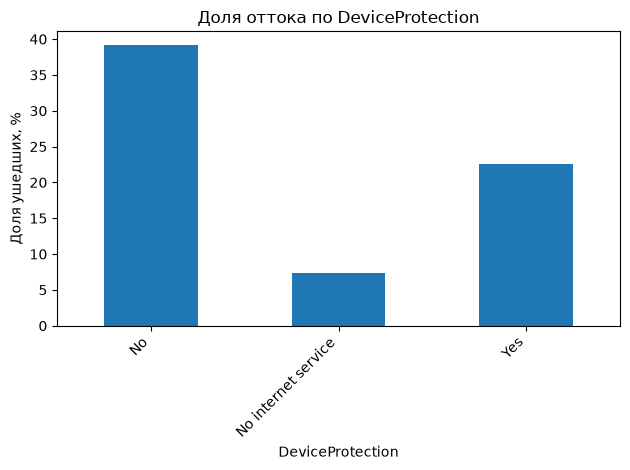


Признак: TechSupport


Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


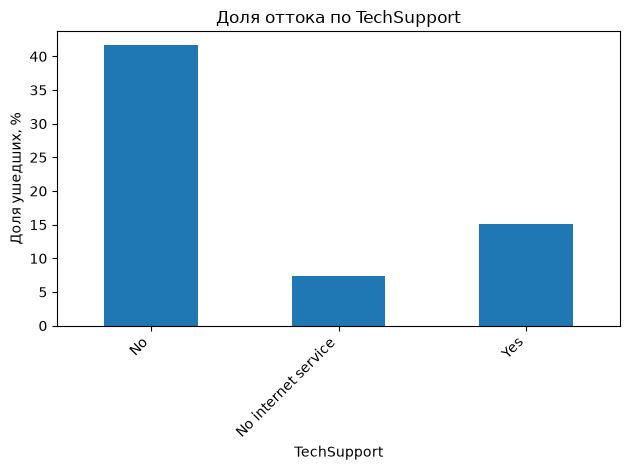


Признак: StreamingTV


Churn,No,Yes
StreamingTV,,
No,1868,942
No internet service,1413,113
Yes,1893,814


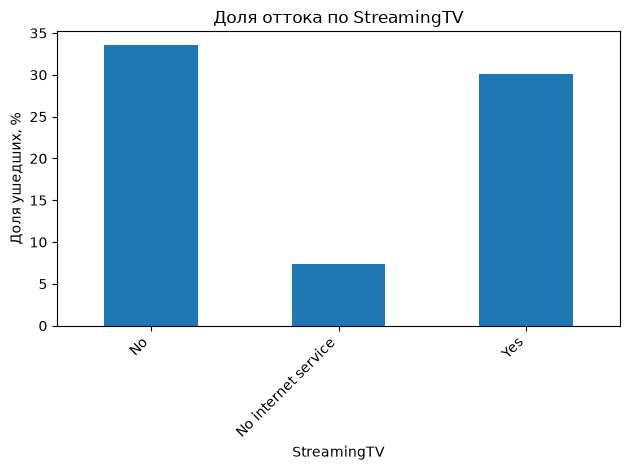


Признак: StreamingMovies


Churn,No,Yes
StreamingMovies,,
No,1847,938
No internet service,1413,113
Yes,1914,818


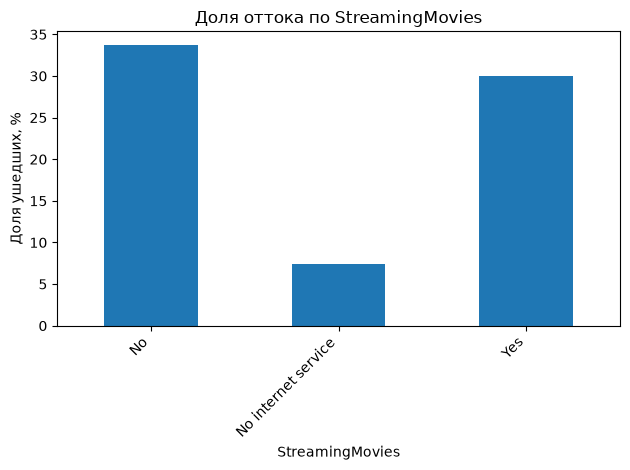


Признак: Contract


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


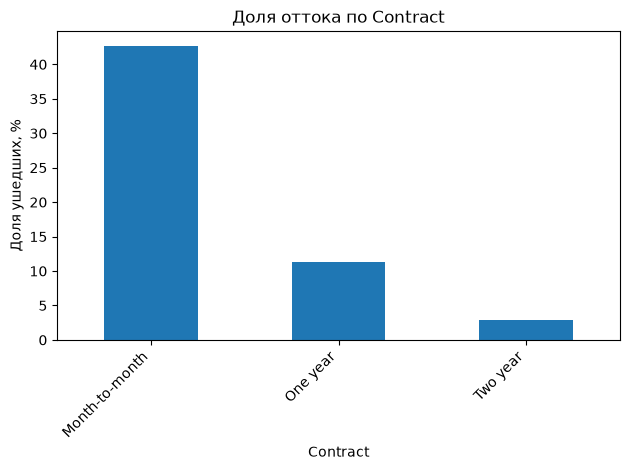


Признак: PaperlessBilling


Churn,No,Yes
PaperlessBilling,,
No,2403,469
Yes,2771,1400


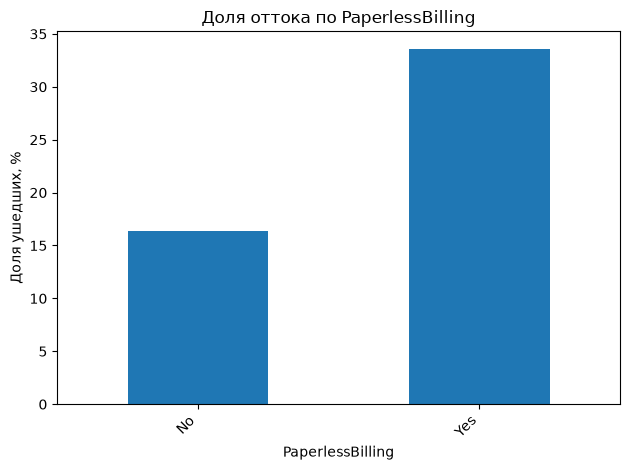


Признак: PaymentMethod


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


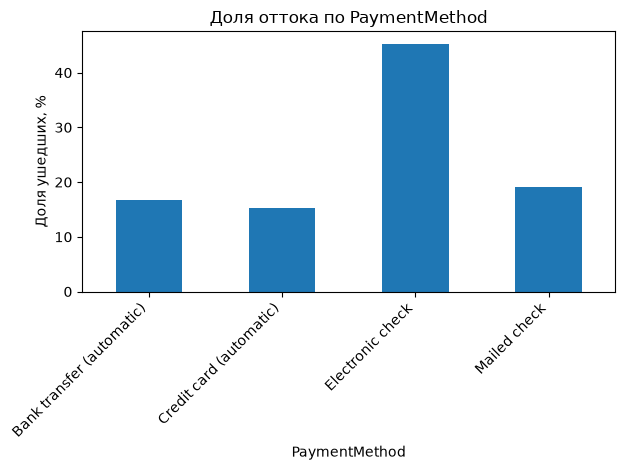

In [13]:
for column in categorical_columns:
    # Количество оставшихся и ушедших в каждой категории
    counts = pd.crosstab(data[column], data['Churn'])

    # Проценты оставшихся и ушедших внутри каждой категории
    percentages = pd.crosstab(
        data[column],
        data['Churn'],
        normalize='index'
    ) * 100

    print(f'\nПризнак: {column}')
    display(counts)

    percentages['Yes'].plot(kind='bar')

    plt.title(f'Доля оттока по {column}')
    plt.xlabel(column)
    plt.ylabel('Доля ушедших, %')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Из построенных диаграмм можно сделать следующие выводы:
- Доли оттока среди мужчин и женщин близки;
- Среди пожилых и людей без партнёра, людей без иждивенцев доля ушедших клиентов заметно выше;
- Доли оттока у клиентов с телефонной связью и без неё близки;
- Среди клиентов, имеющих несколько линий телесвязи доля оттока немного выше;
- Среди клиентов, подключенных к волоконно-оптической связи, доля оттока значительно выше;
- Среди клиентов, не подключенных к различным услугам доля оттока значительно выше, за исключением услуг стриминга ТВ и кинофильмов;
- В основном уходят клиенты с помесячным договором и способом оплаты Electronic check.

---

### 7. Попарный анализ признаков

Построим heatmap и pairplot для числовых признаков:

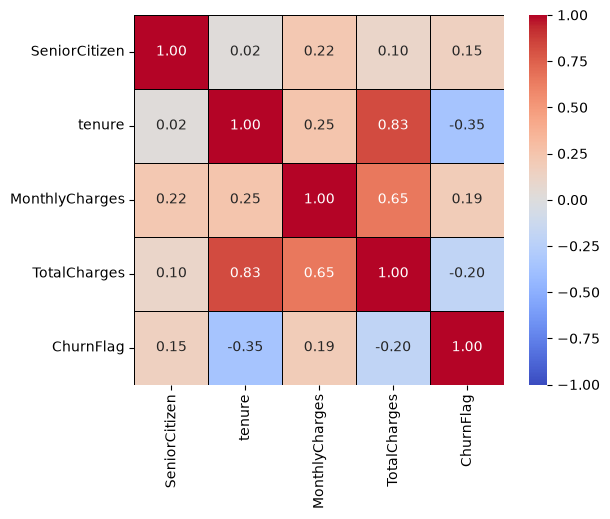

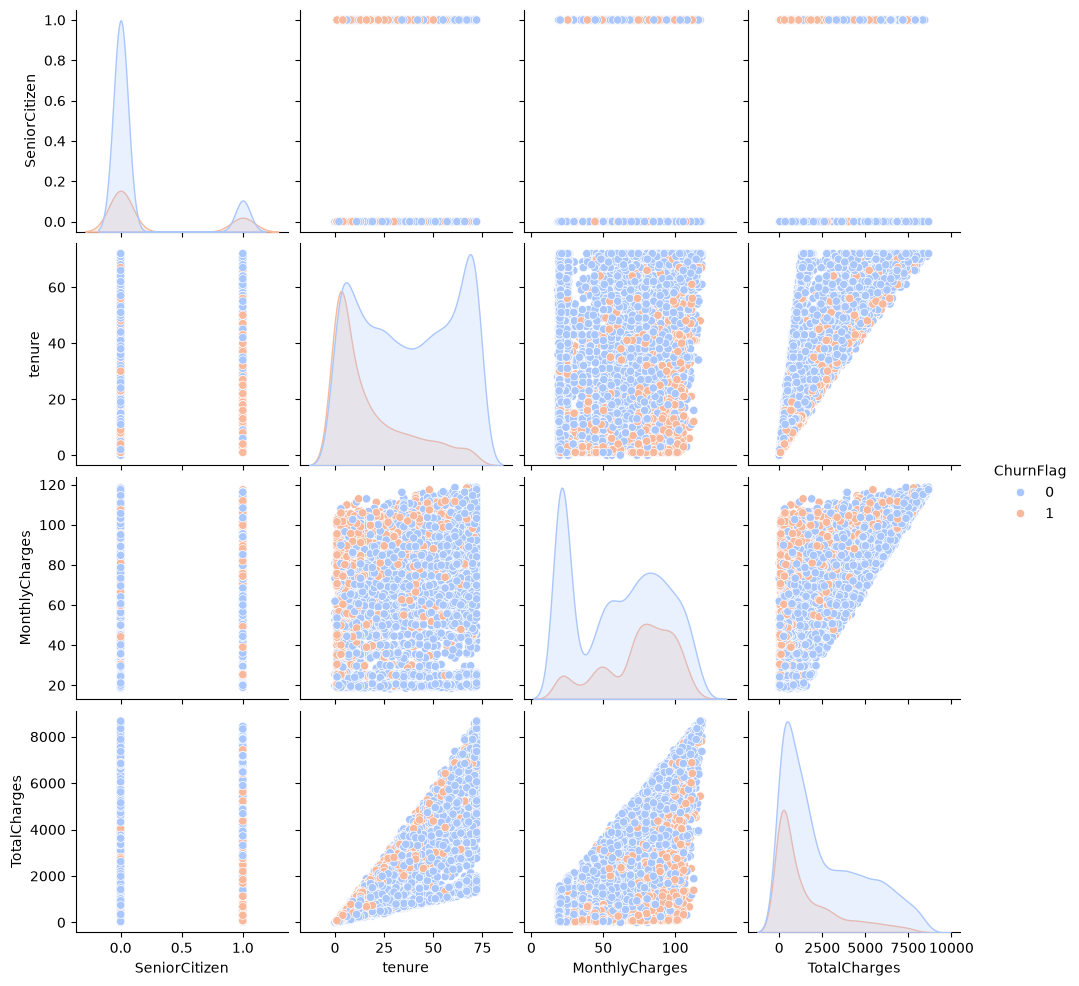

In [14]:
numeric_features = data.copy().select_dtypes(include=('int64', 'float64'))
numeric_features['ChurnFlag'] = data['Churn'].map({'Yes' : 1, 'No' : 0})

sns.heatmap(
    data=numeric_features.corr(),
    annot=True,
    vmin=-1,
    vmax=1,
    cmap='coolwarm',
    fmt='.2f',
    cbar=True,
    square=True,
    linecolor='black',
    linewidths=0.5
)

sns.pairplot(
    data=numeric_features,
    hue='ChurnFlag',
    palette='coolwarm',
    kind='scatter'
)

Между длительностью обслуживания (tenure) и накопленными начислениями (TotalCharges) наблюдается сильная положительная корреляция - 0,83. Накопленные начисления также положительно связаны с ежемесячными начислениями (MonthlyCharges) - 0,65. Это согласуется со смыслом признаков: общая сумма начислений связана как с длительностью обслуживания, так и с размером платежей. Между длительностью обслуживания и ежемесячными начислениями связь слабее - 0,25.

Среди рассмотренных признаков наибольшая по модулю корреляция с таргетом у tenure: −0,35. У TotalCharges она составляет −0,20, у MonthlyCharges - 0,19, у SeniorCitizen - 0,15. При кодировании оттока единицей отрицательный знак соответствует связи больших значений признака с меньшей долей оттока, положительный - с большей. Эти коэффициенты описывают связи, но не устанавливают причины ухода.

На попарных графиках видны зависимости накопленных начислений от длительности обслуживания и ежемесячных начислений. При этом точки ушедших и оставшихся клиентов заметно перекрываются: представленные графики не показывают простого разделения классов.

---

### 8. Выводы и использование результатов EDA

В исследуемой выборке 7043 клиента. Отток отмечен у 1869 клиентов - около 26,5%; остальные 73,5% не отмечены как ушедшие. Таким образом, классы представлены неравномерно.

При проверке качества обнаружены 11 пустых значений (~0.156%) TotalCharges. Все они относятся к клиентам с tenure = 0. Пропуски заполнены нулём на основании гипотезы об отсутствии накопленных начислений у недавно подключённых клиентов. Общая доля пропущенных ячеек = 11/(7043*21), примерно 0,0074%. Полных дубликатов не обнаружено.

Среди ушедших клиентов длительность обслуживания обычно меньше, а ежемесячные начисления - выше. Повышенная доля оттока наблюдается у клиентов с помесячным договором, оптоволоконным интернетом и способом оплаты Electronic check. Доли оттока у мужчин и женщин близки.

Накопленные начисления сильно связаны с длительностью обслуживания: корреляция составляет 0,83. Их корреляция с ежемесячными начислениями составляет 0,65. Среди рассмотренных числовых признаков наиболее выраженная корреляция с оттоком у длительности обслуживания - −0,35. При этом классы на попарных графиках перекрываются.

Полученные результаты планируем использовать при подготовке данных и построении моделей:

- Для TotalCharges сохраним числовой тип и выбранный способ заполнения пропусков нулём у клиентов с tenure = 0. При этом будем учитывать, что такая обработка основана на гипотезе об отсутствии накопленных начислений у недавно подключённых клиентов.

- При разделении данных на обучающую и тестовую выборки планируем сохранить соотношение классов. 

- Из-за сильной связи между tenure и TotalCharges сравним модели с обоими признаками и без одного из них. Удалять признак только на основании корреляции пока не планируем.

- Различия в долях оттока по типу договора, интернет-подключения и способу оплаты используем как гипотезы для последующей проверки. После обучения посмотрим, насколько эти признаки важны для модели и каково качество прогнозов в соответствующих группах.

- Отсутствие заметных различий по полу не будем считать достаточным основанием для немедленного удаления признака: его полезность проверим при сравнении моделей.

- Наблюдаемые связи не будем трактовать как доказанные причины ухода. Рекомендации по удержанию сформулируем как гипотезы, эффективность которых потребуется проверять отдельно.